# 05 · Difficulty models: training, evaluation & explainability
| Model | Idea |
|---|---|
| TF-IDF + LogReg / Ridge | strong linear baseline |
| LightGBM (linguistic features) | interpretable features only |
| LightGBM (linguistic + stacked TF-IDF) | gradient boosting, explained with SHAP |
| BiLSTM + attention | deep learning from scratch with our Word2Vec embeddings |
| DistilBERT multi-task | fine-tuned transformer: level head + score head |
| **Ensemble** | weighted combination, tuned on validation |

Metrics: accuracy, macro-F1, quadratic weighted kappa (ordinal agreement) for the **level**;
MAE, RMSE, Spearman for the **0-100 score**.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

In [2]:
mc = pd.read_csv(REPORTS/'model_comparison.csv'); mc.round(4)

,model,accuracy,macro_f1,qwk,mae,rmse,spearman,band_accuracy
0,LightGBM (linguistic features only),0.7306,0.7334,0.7414,9.3678,12.4120,0.8254,0.6694
1,BiLSTM + attention (from scratch),0.7423,0.7448,0.7664,9.0854,12.0241,0.8369,0.7181
2,TF-IDF + LogReg/Ridge (baseline),0.7617,0.7652,0.7888,9.0533,11.6104,0.8375,0.6596
3,LightGBM (linguistic + stacked TF-IDF),0.7832,0.7858,0.8100,7.3609,10.0847,0.8771,0.7473
4,DistilBERT (multi-task),0.7985,0.7995,0.8310,6.5744,9.4744,0.8931,0.7846
5,Ensemble (final),0.8037,0.8048,0.8351,6.6624,9.5396,0.8919,0.8037


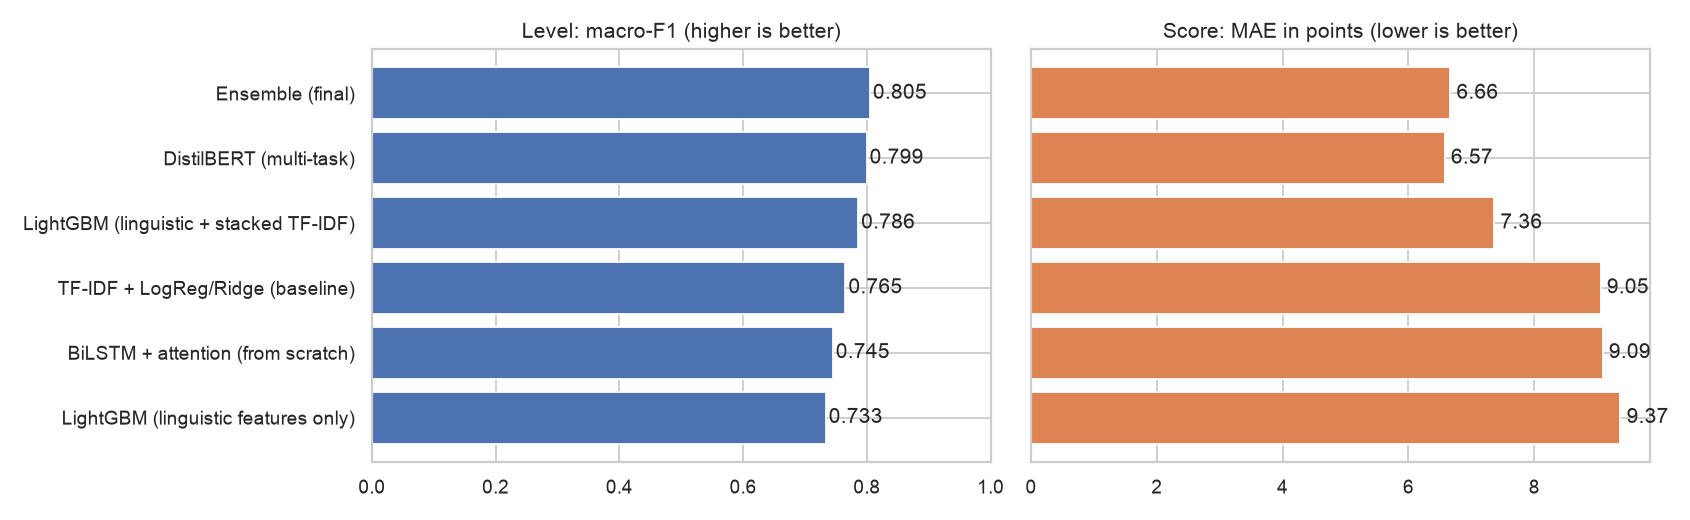

In [3]:
show('model_comparison.png')

In [4]:
h = json.loads((ROOT/'models_store/distilbert_difficulty/history.json').read_text()); pd.DataFrame(h).round(4)

,epoch,train_loss,accuracy,macro_f1,qwk,mae,rmse,spearman,band_accuracy
0,1,0.6473,0.7984,0.8019,0.8327,6.7197,9.3545,0.8970,0.7783
1,2,0.4723,0.8075,0.8090,0.8437,6.3034,9.0949,0.9019,0.7977


Ensemble configuration: {'weights': {'gbm': 0.4, 'bert': 0.5, 'bilstm': 0.1}, 'alpha': 1.0}


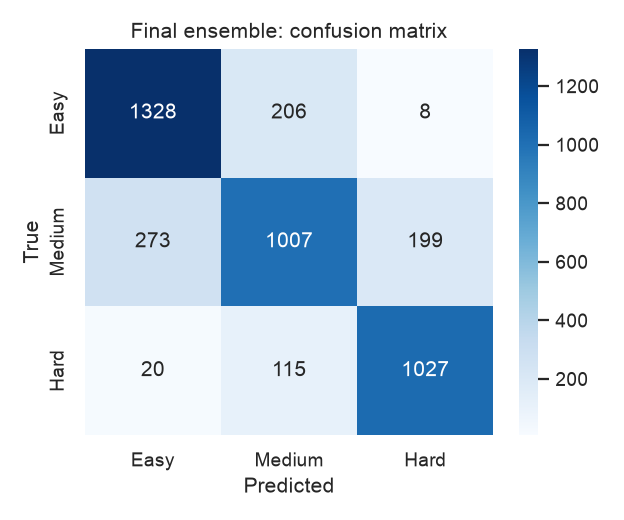

In [5]:
print('Ensemble configuration:', json.loads((ROOT/'models_store/ensemble.json').read_text()))
show('confusion_matrix_ensemble.png')

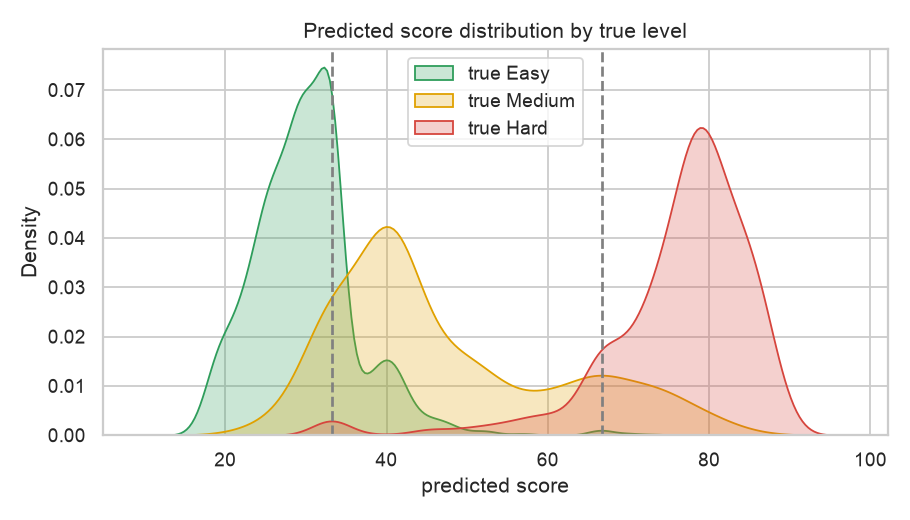

In [6]:
show('score_distribution.png')

## Per-source analysis: does the score follow the educational level?

In [7]:
ps = pd.read_csv(REPORTS/'per_source_results.csv'); ps

,group,n,target_score,mean_pred_score,level_accuracy
0,sciq,300.0,18.0,23.730,0.987
1,commonsense_qa,300.0,25.0,26.387,0.960
2,arc_easy,300.0,28.0,35.477,0.613
3,race_middle,300.0,28.0,31.795,0.780
4,gsm8k,300.0,30.0,31.627,0.977
5,mmlu_elementary,42.0,30.0,37.231,0.786
6,openbookqa,300.0,40.0,38.548,0.853
7,race_high,300.0,42.0,37.950,0.717
8,arc_challenge,258.0,52.0,37.764,0.558
9,mmlu_highschool,300.0,52.0,51.438,0.843


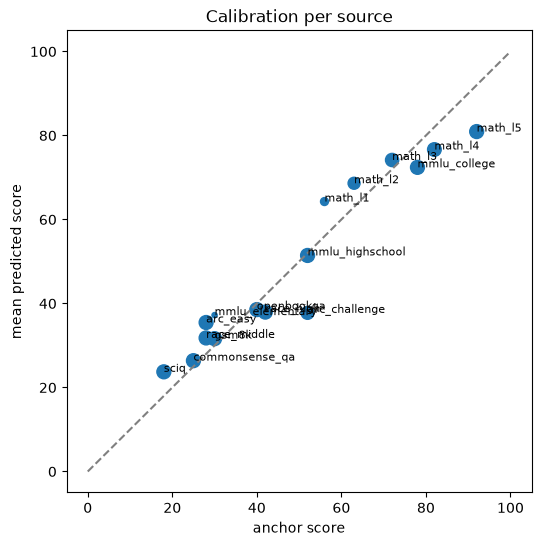

In [8]:
plt.figure(figsize=(6,6)); plt.scatter(ps.target_score, ps.mean_pred_score, s=ps.n/3)
for _,r in ps.iterrows(): plt.annotate(r.group, (r.target_score, r.mean_pred_score), fontsize=8)
plt.plot([0,100],[0,100],'--',c='grey'); plt.xlabel('anchor score'); plt.ylabel('mean predicted score'); plt.title('Calibration per source'); plt.show()

## Explainability

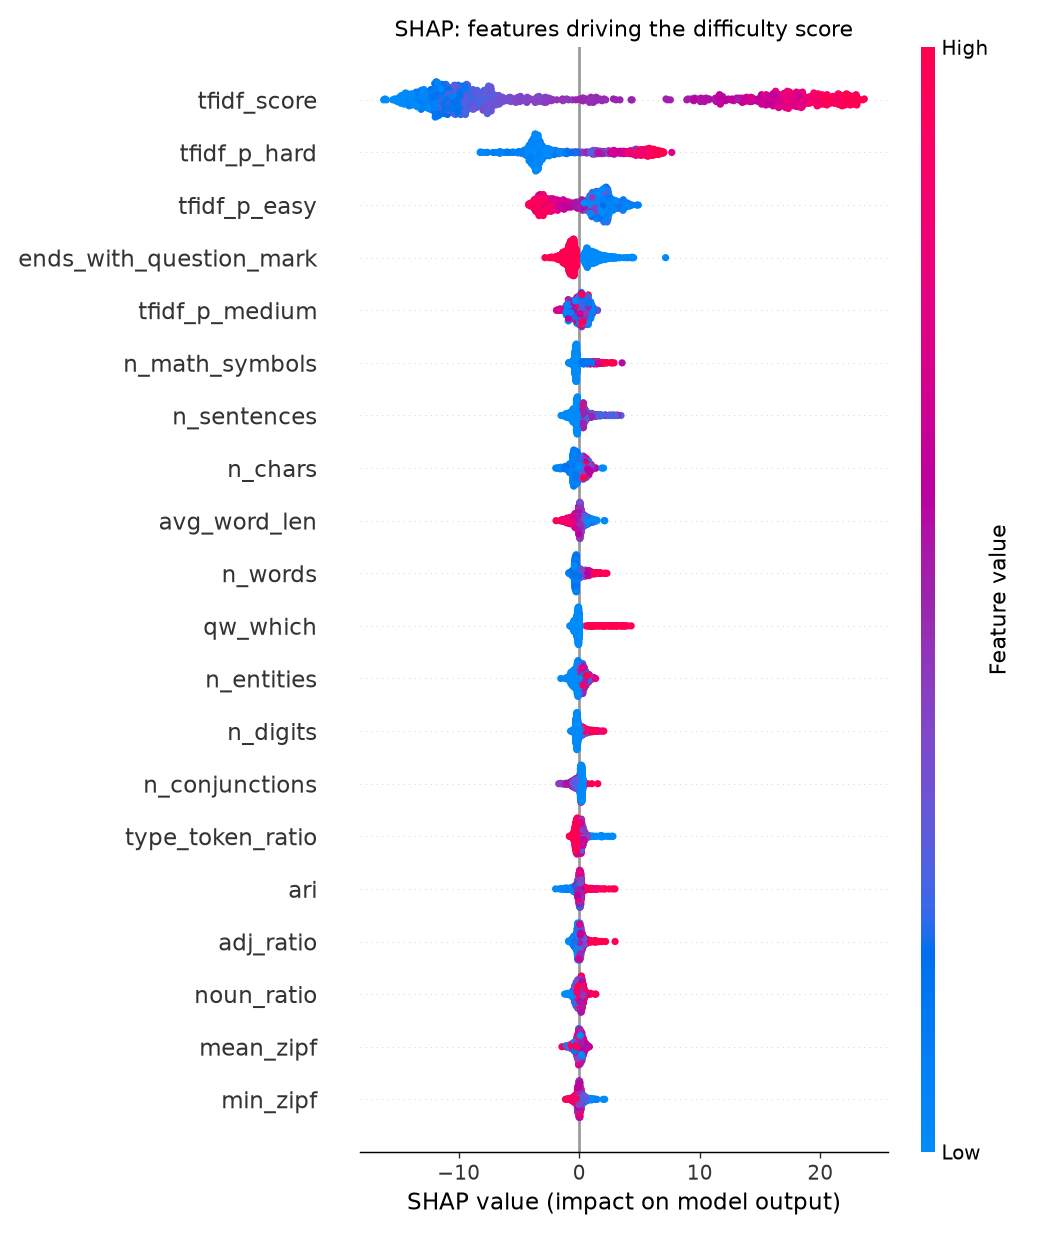

In [9]:
show('shap_summary.png')

In [10]:
pd.read_csv(REPORTS/'shap_mean_abs.csv').head(15)

,Unnamed: 0,mean_abs_shap
0,tfidf_score,12.365401
1,tfidf_p_hard,3.747312
2,tfidf_p_easy,2.104625
3,ends_with_question_mark,0.985140
4,tfidf_p_medium,0.507847
5,n_math_symbols,0.506222
6,n_sentences,0.504827
7,n_chars,0.416350
8,avg_word_len,0.394650
9,n_words,0.381694


## Error analysis

In [11]:
tp = pd.read_csv(REPORTS/'test_predictions.csv')
from src.config import LEVELS
tp['pred_level'] = tp.pred_label.map(dict(enumerate(LEVELS)))
err = tp[tp.level != tp.pred_level]
print(f'{len(err)} errors of {len(tp)}'); display(pd.crosstab(err.group, err.pred_level))
err.sample(12, random_state=0)[['group','question','level','pred_level','pred_score']]

821 errors of 4183


pred_level,Easy,Hard,Medium
group,,,
arc_challenge,114,0,0
arc_easy,0,0,116
commonsense_qa,0,0,12
gsm8k,0,5,2
math_l1,2,33,0
math_l2,11,136,0
math_l3,5,0,43
math_l4,6,0,21
math_l5,4,0,8


,group,question,level,pred_level,pred_score
3338,math_l2,My school's math club has 6 boys and 8 girls. I need to select a team to send to the state math competition. We want...,Medium,Hard,70.166981
3611,arc_challenge,In which state of matter does water have a definite shape and volume?,Medium,Easy,33.300000
2428,mmlu_highschool,"An algorithm for finding the average of N numbers is average = sum / N, where N and sum are both integers. In a prog...",Medium,Hard,76.741157
2600,math_l2,"Daniel works at an electronics store, and he claims that the popularity of a toaster (measured in number of sales) i...",Medium,Hard,71.170663
505,race_high,What is the ultimate title of wrestling?,Medium,Easy,30.076178
86,math_l3,What is the value of the following expression: 1 - 4 + 7 - 10 + 13 - * s - 46 + 49 - 52 + 55 ?,Hard,Medium,60.362297
129,arc_challenge,How did scientists arrive at the theory of plate tectonics?,Medium,Easy,33.300000
2198,race_high,The writer was not allowed to stay at the house because _,Medium,Easy,32.831203
4124,math_l2,Solve for x in the equation 2^ (16^x) = 16^ (2^x) .,Medium,Hard,69.673099
3576,arc_easy,A 13-year-old boy has blue eyes. Which statement concerning his eye color is correct?,Easy,Medium,51.467810


## Using the predictor

In [12]:
from src.predict import get_predictor
p = get_predictor()
tests = ['What is the capital of France?', 'Explain why the sky appears blue during the day.',
         'A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration.',
         'Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.',
         'Find all positive integers n such that n^2 + 1 is divisible by n + 1.']
p.predict_batch(tests)[['question','level','score','confidence','p_easy','p_medium','p_hard']]

W1116 23:28:50.886000 60819 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

,question,level,score,confidence,p_easy,p_medium,p_hard
0,What is the capital of France?,Easy,29.8,0.837,0.837,0.147,0.016
1,Explain why the sky appears blue during the day.,Medium,36.9,0.540,0.452,0.540,0.008
2,A car accelerates uniformly from 10 m/s to 30 m/s in 5 seconds. Calculate its acceleration.,Medium,54.5,0.782,0.101,0.782,0.117
3,Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.,Medium,58.5,0.798,0.008,0.798,0.194
4,Find all positive integers n such that n^2 + 1 is divisible by n + 1.,Hard,80.6,0.878,0.008,0.114,0.878


In [13]:
r = p.predict('Prove that there are infinitely many prime numbers.')
print(r['level'], r['score'], r['probabilities']); print('SHAP:', r['shap'][:5]); print('Attention:', r.get('attention'))

Hard 70.3 {'Easy': 0.032, 'Medium': 0.363, 'Hard': 0.605}
SHAP: [('tfidf_score', 14.29, 62.576), ('tfidf_p_hard', 2.98, 0.657), ('tfidf_p_easy', 2.56, 0.026), ('ends_with_question_mark', 1.68, 0.0), ('n_chars', -1.07, 51.0)]
Attention: [('prove', 0.16200000047683716), ('that', 0.026000000536441803), ('there', 0.00800000037997961), ('are', 0.004000000189989805), ('infinitely', 0.22100000083446503), ('many', 0.1340000033378601), ('prime', 0.3070000112056732), ('numbers', 0.13899999856948853)]
